# Classical image-descriptor baseline for blueberry canopy-size classification (RBF-SVM + Random Forest)

**Paper:** *Statistical Descriptors of β-Variational Autoencoder Latent Feature Maps for Image-Based Blueberry Canopy-Size Phenotyping* — Agronomy 16(21):2222 (2026), MDPI. DOI: [10.3390/agronomy16212222](https://doi.org/10.3390/agronomy16212222)

**Author code:** `agmzaman/BlueberryLatentMapPhenotyping` @ commit `a9be840397fc06522889cbfcee0b928d1002196c` (MIT license). **Dataset:** [Zenodo record 19597014](https://doi.org/10.5281/zenodo.19597014) (CC-BY-4.0, 2,043 RGB images, single 22.5 GB 7z archive).

**Scope of this notebook (partial demonstration).** This notebook reproduces the paper's **classical image-descriptor baseline subsection** end-to-end with the authors' unmodified pipeline (their scripts `17`–`19`): for each of the 2,043 field images it computes an automatic ExG+Otsu vegetation mask, extracts **22 engineered descriptors** (6 morphology, 6 colour, 10 GLCM texture), then trains and evaluates **RBF-SVM** and **Random Forest** canopy-size classifiers (classes: Very Small / Small / Medium / Large) on the paper's four evaluation splits (stratified-random 1,225/409/409 with seed 131, plus session-held-out S1–S3). The paper's β-VAE and EfficientNet-B0 subsections are **out of scope**: no trained weights are released, so those parts would require full retraining.

**Execution status:** executed end-to-end in a fresh Google Colab **CPU** runtime (no GPU is needed — this path uses only OpenCV/NumPy/scikit-learn). Outputs below are from that run.

**AI-note (EN):** The scientific code executed here is the authors' own pinned Python code, downloaded unmodified from their repository. Notebook-specific glue (dataset download/extraction, config generation, previews, plots) was written for this notebook and is marked as such. The executed example and listed checks were validated, but untested behaviour is not guaranteed, and a single-split demonstration does not verify the paper's full published results.

**日本語:** このノートブックは、論文の「古典的な画像記述子ベースライン」(著者スクリプト 17–19) をそのまま実行します。ExG+Otsu による自動マスク、22 個の形態・色・GLCM 記述子、RBF-SVM とランダムフォレストによるキャナピーサイズ (4 クラス) 分類を、論文と同じ 4 つのデータ分割で再現します。β-VAE と EfficientNet-B0 の部分は学習済み重みが非公開のため対象外です。CPU ランタイムで動作します (GPU 不要)。実行時間の目安は 60–150 分、ダウンロードは約 22.5 GB です。

## Runtime selection and Run-all instructions

**Select Runtime → Change runtime type → CPU** (standard CPU runtime is sufficient; a GPU runtime also works but provides no benefit). Then **Runtime → Run all**.

**Cost warnings (measured on the validation run — see outputs):** the dataset is distributed by the authors as a **single 22.5 GB 7z archive** on Zenodo, so the full archive must be downloaded and extracted even though only images are needed (the annotations CSV inside the archive is not used by this baseline). Disk needs ~50 GB peak; Colab's default CPU disk is sufficient. Expect roughly 60–150 minutes end-to-end, dominated by the download, extraction, and descriptor extraction over 2,043 images.

**Limitations:** this is a partial reproduction of one paper subsection; results from a fresh training run may differ slightly from the published numbers across software versions and hardware (the authors state this in their README). Reference values committed by the authors in the same repository revision are compared against our results below.

**日本語:** ランタイムは **CPU** を選択してください (GPU は不要です)。その後「ランタイム → すべてのセルを実行」を実行してください。データセットは 22.5 GB の単一アーカイブのため、全文のダウンロードと展開が必要です。全体の目安は 60–150 分です。

In [ ]:
import importlib
import subprocess
import sys

REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "cv2": "opencv-python",
    "sklearn": "scikit-learn",
    "PIL": "Pillow",
    "yaml": "PyYAML",
    "joblib": "joblib",
    "requests": "requests",
    "torch": "torch",
    "torchvision": "torchvision",
}
missing = []
for module_name, package_name in REQUIRED.items():
    try:
        module = importlib.import_module(module_name)
        version = getattr(module, "__version__", "n/a")
        print(f"{module_name:12s} {version}")
    except ImportError:
        missing.append(package_name)
        print(f"{module_name:12s} MISSING")
if missing:
    print("Installing missing packages:", missing)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--no-input", *missing],
        check=True,
    )
import platform
print()
print("Python:", platform.python_version())
print("Platform:", platform.platform())

numpy        2.4.6


pandas       2.2.3
cv2          5.0.0


sklearn      1.6.1
PIL          11.3.0
yaml         6.0.3
joblib       1.6.0
requests     2.32.4


torch        2.14.1+cpu


torchvision  0.29.1+cpu

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39


## Step 1 — Retrieve the authors' pinned pipeline code

We download the exact files needed for the descriptor baseline (entry-point scripts `17`–`19` plus the library modules and configs they import) from the authors' repository at the pinned commit `a9be840397fc06522889cbfcee0b928d1002196c`. The primary route is the jsDelivr CDN mirror of the commit; GitHub raw is a documented fallback. Every Python file is compile-checked and every file size is verified against the repository tree metadata, so we fail loudly on truncated or wrong content. The code is MIT-licensed; the license file is included.

**日本語:** 著者のリポジトリから、ピン留めしたコミット (`a9be840397fc06522889cbfcee0b928d1002196c`) のコードを取得します (jsDelivr CDN、フォールバックは GitHub raw)。取得した Python ファイルはコンパイルチェックとサイズ検証を行います。ライセンスは MIT です。

In [ ]:
import requests

COMMIT = "a9be840397fc06522889cbfcee0b928d1002196c"
REPO = "agmzaman/BlueberryLatentMapPhenotyping"
ROOT = None  # set after the code is in place

CODE_FILES = {
    "scripts/_bootstrap.py": 257,
    "scripts/17_extract_image_descriptors.py": 1492,
    "scripts/18_train_descriptor_classifiers.py": 1625,
    "scripts/19_summarize_descriptor_results.py": 1519,
    "src/blueberry_latent_map_phenotyping/__init__.py": 22,
    "src/blueberry_latent_map_phenotyping/config.py": 18760,
    "src/blueberry_latent_map_phenotyping/data.py": 21363,
    "src/blueberry_latent_map_phenotyping/image_descriptor_pipeline.py": 25269,
    "src/blueberry_latent_map_phenotyping/image_descriptor_settings.py": 7471,
    "src/blueberry_latent_map_phenotyping/image_descriptors.py": 21130,
    "src/blueberry_latent_map_phenotyping/paths.py": 9853,
    "src/blueberry_latent_map_phenotyping/runtime.py": 2083,
    "configs/config.example.yaml": 4740,
    "configs/image_descriptor.yaml": 1129,
    "requirements.txt": 330,
    "LICENSE": 1093,
}


def fetch_repo_file(relative_path):
    """Fetch one pinned file, trying jsDelivr first and GitHub raw as fallback."""
    urls = [
        f"https://cdn.jsdelivr.net/gh/{REPO}@{COMMIT}/{relative_path}",
        f"https://raw.githubusercontent.com/{REPO}/{COMMIT}/{relative_path}",
    ]
    last_error = None
    for url in urls:
        try:
            response = requests.get(url, timeout=120)
            response.raise_for_status()
            return response.content, url
        except Exception as error:
            last_error = error
            print(f"  {url.split('/')[2]} failed for {relative_path}: {error}")
    raise RuntimeError(f"Could not fetch {relative_path}: {last_error}")


from pathlib import Path

project_root = Path("/content/BlueberryLatentMapPhenotyping")
for relative_path, expected_size in CODE_FILES.items():
    content, used_url = fetch_repo_file(relative_path)
    if len(content) != expected_size:
        raise RuntimeError(
            f"{relative_path}: expected {expected_size} bytes, got {len(content)}"
        )
    target = project_root / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
    if relative_path.endswith(".py"):
        compile(content.decode("utf-8"), relative_path, "exec")
print(f"Retrieved {len(CODE_FILES)} pinned code files (all sizes verified).")
ROOT = project_root
print("Project root:", ROOT)

Retrieved 16 pinned code files (all sizes verified).
Project root: /content/BlueberryLatentMapPhenotyping


## Step 2 — Retrieve the paper's evaluation splits

The four evaluation partitions used by every method in the paper ship inside the author repository as small CSV files: the stratified-random split (1,225 train / 409 validation / 409 test, seed 131) and the session-held-out splits S1–S3 (each holds out one acquisition session for testing). These are measured inputs, so we fetch them from the same pinned commit and verify that the stratified split covers exactly 2,043 unique images with the four canopy-size classes.

**日本語:** 論文の 4 つの評価分割 (層別無作為 + セッション型抜き S1–S3) を同じコミットから取得し、層別分割が 2,043 枚・4 クラスをカバーすることを検証します。

In [ ]:
SPLIT_FILES = {
    "data/splits/train.csv": 38964,
    "data/splits/validation.csv": 13026,
    "data/splits/test.csv": 13030,
    "data/splits/split_summary.csv": 470,
    "data/session_held_out_splits/S1/train.csv": 50946,
    "data/session_held_out_splits/S1/validation.csv": 17100,
    "data/session_held_out_splits/S1/test.csv": 19507,
    "data/session_held_out_splits/S2/train.csv": 48482,
    "data/session_held_out_splits/S2/validation.csv": 16284,
    "data/session_held_out_splits/S2/test.csv": 22787,
    "data/session_held_out_splits/S3/train.csv": 40217,
    "data/session_held_out_splits/S3/validation.csv": 13525,
    "data/session_held_out_splits/S3/test.csv": 33811,
}
for relative_path, expected_size in SPLIT_FILES.items():
    content, used_url = fetch_repo_file(relative_path)
    if len(content) != expected_size:
        raise RuntimeError(
            f"{relative_path}: expected {expected_size} bytes, got {len(content)}"
        )
    target = ROOT / relative_path
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(content)
print(f"Retrieved {len(SPLIT_FILES)} split files (all sizes verified).")

import pandas as pd

stratified = pd.concat(
    [
        pd.read_csv(ROOT / "data/splits" / name)
        for name in ["train.csv", "validation.csv", "test.csv"]
    ],
    ignore_index=True,
)
print("Stratified-random split rows:", len(stratified))
assert len(stratified) == 2043, "The stratified split must cover exactly 2,043 images."
assert stratified["image_filename"].is_unique, "Duplicate image filenames in split."
print("Classes:", sorted(stratified["size_class"].unique()))
print("Class counts:")
print(stratified["size_class"].value_counts().to_string())
print()
print("Example split rows:")
display(stratified.head(3))

Retrieved 13 split files (all sizes verified).
Stratified-random split rows: 2043
Classes: ['Large', 'Medium', 'Small', 'Very Small']
Class counts:
size_class
Small         849
Very Small    646
Medium        422
Large         126

Example split rows:


,image_filename,size_class
0,2025-08-22/IMG_0119.JPG,Very Small
1,2025-08-22/IMG_9896.JPG,Small
2,2025-08-07/IMG_9607.JPG,Medium


## Step 3 — Download the blueberry canopy dataset from Zenodo

The 2,043 near-top-view RGB images (four acquisition sessions in August–September 2025 at the Rohu Experimental Site, Estonia) are published as **one 22.5 GB 7z archive** (CC-BY-4.0). We query the public Zenodo record API, pin the file identity from its metadata (name, exact size, MD5), stream the download with automatic resume, and verify the MD5 digest before extraction. At ~20 MB/s this takes roughly 20 minutes; on a slow link it can take substantially longer.

**日本語:** データセット (2,043 枚の RGB 画像、CC-BY-4.0) は Zenodo 上で 22.5 GB の単一 7z アーカイブです。公開記録 API からファイル情報を取得し、レジューム対応のストリーミング下载の後、MD5 を検証します。20 分前後かかります。

In [ ]:
import hashlib
import json
import os
import time

import requests

RECORD_URL = "https://zenodo.org/api/records/19597014"
EXPECTED_FILE = "blueberry_canopy_dataset.7z"
EXPECTED_SIZE = 22543991123
EXPECTED_MD5 = "185f6bd7dcf87de8ec57132f58b8f8d8"
ARCHIVE_PATH = "/content/blueberry_canopy_dataset.7z"

record = requests.get(RECORD_URL, timeout=120)
record.raise_for_status()
record = record.json()
assert record["metadata"]["title"].startswith(
    "High-resolution RGB image dataset of blueberry plants"
), "Unexpected Zenodo record identity."
zenodo_file = record["files"][0]
assert zenodo_file["key"] == EXPECTED_FILE, zenodo_file["key"]
assert zenodo_file["size"] == EXPECTED_SIZE, zenodo_file["size"]
assert zenodo_file["checksum"].split(":")[-1] == EXPECTED_MD5
download_url = zenodo_file["links"]["self"]
print("Zenodo record 19597014 verified:", EXPECTED_FILE,
      f"({EXPECTED_SIZE / 1e9:.2f} GB)")

for attempt in range(20):
    downloaded = os.path.getsize(ARCHIVE_PATH) if os.path.exists(ARCHIVE_PATH) else 0
    if downloaded >= EXPECTED_SIZE:
        break
    headers = {"Range": f"bytes={downloaded}-"} if downloaded else {}
    started = time.time()
    try:
        with requests.get(download_url, headers=headers, stream=True, timeout=(30, 180)) as response:
            response.raise_for_status()
            with open(ARCHIVE_PATH, "ab" if downloaded else "wb") as handle:
                for chunk in response.iter_content(chunk_size=8 * 1024 * 1024):
                    handle.write(chunk)
        print(f"  pass {attempt + 1}: total {os.path.getsize(ARCHIVE_PATH) / 1e9:.2f} GB "
              f"in {time.time() - started:.0f} s", flush=True)
    except Exception as error:
        print(f"  pass {attempt + 1} interrupted ({error}); resuming.", flush=True)
        time.sleep(5)
if os.path.getsize(ARCHIVE_PATH) != EXPECTED_SIZE:
    raise RuntimeError("Archive download did not reach the expected size.")

digest = hashlib.md5()
with open(ARCHIVE_PATH, "rb") as handle:
    for chunk in iter(lambda: handle.read(16 * 1024 * 1024), b""):
        digest.update(chunk)
assert digest.hexdigest() == EXPECTED_MD5, "MD5 mismatch after download."
print("Download complete and MD5 verified:", EXPECTED_MD5)

Zenodo record 19597014 verified: blueberry_canopy_dataset.7z (22.54 GB)


  pass 1: total 22.54 GB in 5738 s


Download complete and MD5 verified: 185f6bd7dcf87de8ec57132f58b8f8d8


## Step 4 — Extract the archive and validate the image inventory

We extract the archive with `7z` (installing `p7zip-full` only if the runtime lacks it) and validate the result against the split manifests: exactly 2,043 image files must exist at the dataset-relative paths referenced by the stratified split, across the four acquisition-session folders. The verified archive is then deleted to free disk. The polygon annotations CSV bundled in the archive is not used by this baseline (the descriptor pipeline builds its own ExG+Otsu masks), but we report whether it is present.

**日本語:** アーカイブを 7z で展開し、分割マニフェストどおり 2,043 枚の画像が存在することを検証した後、アーカイブを削除してディスクを空けます。アノテーション CSV はこのベースラインでは使用しません。

In [ ]:
import shutil
import subprocess

if shutil.which("7z") is None:
    print("Installing p7zip-full ...")
    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "p7zip-full"],
        check=True,
        stdout=subprocess.PIPE,
    )
subprocess.run(
    ["7z", "x", "-y", "-bso0", "-bsp0", "-o/content", ARCHIVE_PATH],
    check=True,
)
print("Extraction finished.")

from pathlib import Path

dataset_root = None
for candidate in [Path("/content/blueberry_canopy_dataset"), *Path("/content").glob("*/blueberry_canopy_dataset")]:
    if (candidate / "images").is_dir():
        dataset_root = candidate
        break
if dataset_root is None:
    raise RuntimeError("Could not locate the extracted blueberry_canopy_dataset/images folder.")
print("Dataset root:", dataset_root)

session_dirs = sorted(entry.name for entry in (dataset_root / "images").iterdir() if entry.is_dir())
print("Session folders:", session_dirs)
on_disk = sum(1 for path in (dataset_root / "images").rglob("*") if path.is_file())
print("Image files on disk:", on_disk)

annotation_csv = dataset_root / "annotations" / "blueberry_annotations_labeled.csv"
print("Annotation CSV present (not used by this baseline):", annotation_csv.is_file())

image_root = dataset_root / "images"
missing = [
    relative
    for relative in stratified["image_filename"]
    if not (image_root / relative).is_file()
]
if missing:
    raise RuntimeError(f"{len(missing)} split-referenced images are missing, e.g. {missing[:3]}")
assert on_disk == 2043, f"Expected 2,043 images, found {on_disk}."
print("All 2,043 split-referenced images are present.")

os.remove(ARCHIVE_PATH)
print("Verified archive deleted to free disk.")

Extraction finished.
Dataset root: /content/blueberry_canopy_dataset
Session folders: ['2025-08-07', '2025-08-22', '2025-09-05', '2025-09-29']
Image files on disk: 2043
Annotation CSV present (not used by this baseline): True
All 2,043 split-referenced images are present.


Verified archive deleted to free disk.


## Step 5 — Generate the author configuration (`configs/config.yaml`)

The author scripts read `configs/config.yaml`, which the README instructs users to create from `config.example.yaml` by setting `dataset.root` to the extracted dataset folder. We do exactly that (the only edit is `dataset.root`); every other setting stays at the released values. `validate_config` runs with `validate_dataset=False` because the author scripts only need the images, not the annotation CSV.

**日本語:** README の指示どおり、`config.example.yaml` から `config.yaml` を作成します。変更は `dataset.root` のみで、その他の設定はすべてリリース値のままです。

In [ ]:
import yaml

config = yaml.safe_load((ROOT / "configs" / "config.example.yaml").read_text())
config["dataset"]["root"] = str(dataset_root)
with (ROOT / "configs" / "config.yaml").open("w", encoding="utf-8") as handle:
    yaml.safe_dump(config, handle, sort_keys=False)
print("Wrote", ROOT / "configs" / "config.yaml")
print(yaml.safe_dump(config["dataset"], sort_keys=False))

Wrote /content/BlueberryLatentMapPhenotyping/configs/config.yaml
root: /content/blueberry_canopy_dataset
annotation_csv: annotations/blueberry_annotations_labeled.csv
image_directory: images
image_column: image_filename
label_column: size_class
classes:
- Very Small
- Small
- Medium
- Large
expected_total: 2043



## Step 6 — Preview real inputs and the automatic vegetation mask

Before the long extraction we look at the actual data. For one deterministic sample per canopy-size class (the alphabetically first `train`-split image of each class) we render the original 512×512 resize and the **automatic ExG+Otsu vegetation mask** computed with the authors' own functions (`normalized_rgb_and_excess_green`, `automatic_vegetation_mask`), plus the 22 descriptor values for those samples. This preview is an additional visualization created for this notebook using author code — the mask is the pipeline's own automatic segmentation, **not** a reference annotation from the dataset.

**日本語:** クラスごとに 1 枚 (train 分割の各クラスで辞書順最初の画像) を選び、著者コードの関数で ExG+Otsu マスクを計算して可視化します。赤い輪郭はパイプラインが自動生成したマスク境界であり、データセットの正解アノテーションではありません。

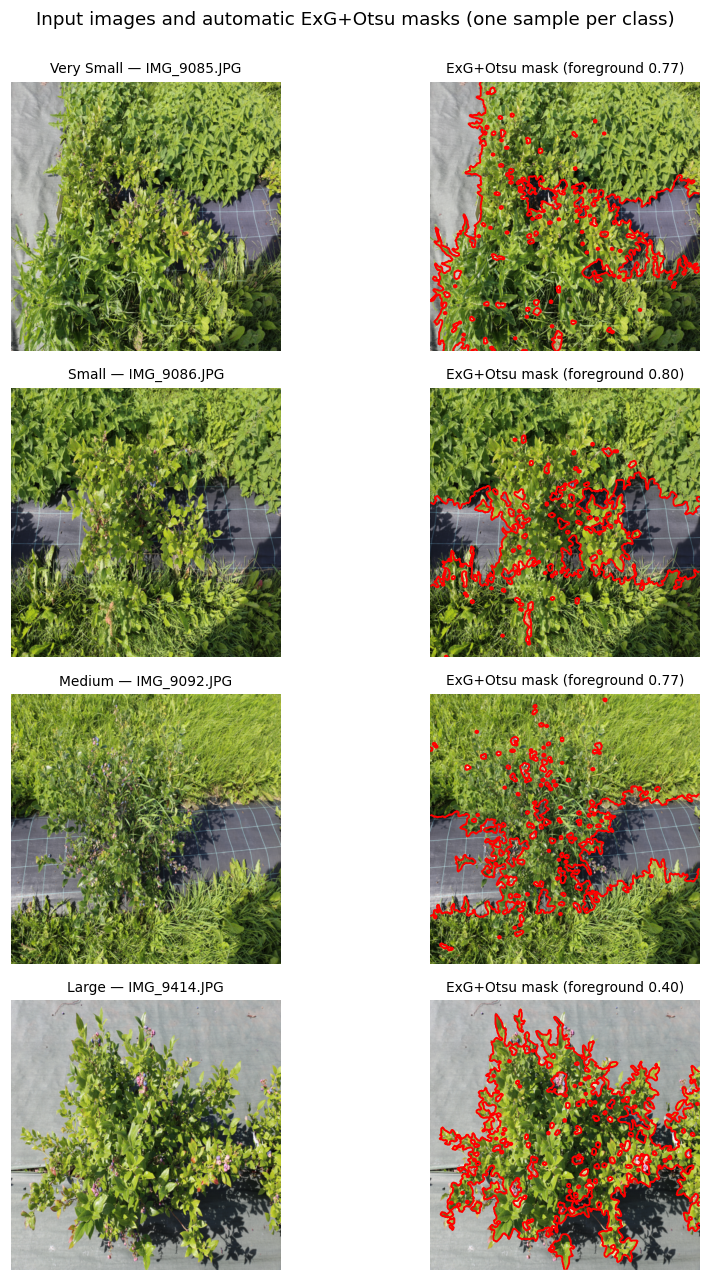

,morphology_area_fraction,morphology_width_fraction,morphology_height_fraction,morphology_normalized_perimeter,morphology_solidity,morphology_eccentricity,size_class,image
0,0.765213,1.000000,1.000000,12.736208,0.815613,0.613545,Very Small,2025-08-07/IMG_9085.JPG
1,0.796101,1.000000,1.000000,12.750019,0.796101,0.488885,Small,2025-08-07/IMG_9086.JPG
2,0.765766,1.000000,1.000000,13.888019,0.765766,0.504766,Medium,2025-08-07/IMG_9092.JPG
3,0.403049,0.964844,0.966797,17.879305,0.539182,0.514599,Large,2025-08-07/IMG_9414.JPG


Each sample yields 22 descriptors.


In [ ]:
import sys
import time

import matplotlib.pyplot as plt

sys.path.insert(0, str(ROOT / "src"))
from blueberry_latent_map_phenotyping.config import load_config
from blueberry_latent_map_phenotyping.image_descriptor_settings import (
    config_with_image_descriptor_settings,
)
from blueberry_latent_map_phenotyping.image_descriptors import (
    automatic_vegetation_mask,
    extract_image_descriptor_values,
    image_descriptor_columns,
    normalized_rgb_and_excess_green,
    read_resized_rgb,
)
from blueberry_latent_map_phenotyping.paths import dataset_image_root

notebook_config = config_with_image_descriptor_settings(
    load_config(ROOT / "configs" / "config.yaml", False),
    ROOT / "configs" / "image_descriptor.yaml",
)
image_root = dataset_image_root(notebook_config)

train_frame = pd.read_csv(ROOT / "data/splits/train.csv")
class_order = notebook_config["dataset"]["classes"]
samples = [
    train_frame[train_frame["size_class"] == class_name]
    .sort_values("image_filename")
    .iloc[0]
    for class_name in class_order
]

figure, axes = plt.subplots(len(samples), 2, figsize=(9, 2.9 * len(samples)), dpi=110)
descriptor_rows = []
for row_index, sample in enumerate(samples):
    image_path = image_root / sample["image_filename"]
    rgb = read_resized_rgb(image_path, notebook_config["image_descriptors"]["image_size"])
    _, excess_green = normalized_rgb_and_excess_green(rgb)
    mask, diagnostics = automatic_vegetation_mask(notebook_config, excess_green)
    descriptors, _ = extract_image_descriptor_values(notebook_config, rgb)
    descriptor_rows.append({"size_class": sample["size_class"],
                            "image": sample["image_filename"], **descriptors})

    label = f"{sample['size_class']} — {Path(sample['image_filename']).name}"
    axes[row_index, 0].imshow(rgb)
    axes[row_index, 0].set_title(label, fontsize=9)
    axes[row_index, 0].axis("off")
    axes[row_index, 1].imshow(rgb)
    axes[row_index, 1].contour(mask.astype(float), levels=[0.5], colors="red", linewidths=1.2)
    axes[row_index, 1].set_title(
        f"ExG+Otsu mask (foreground {diagnostics['foreground_fraction_after_cleanup']:.2f})",
        fontsize=9,
    )
    axes[row_index, 1].axis("off")
figure.suptitle("Input images and automatic ExG+Otsu masks (one sample per class)", y=1.0)
figure.tight_layout()
plt.show()

descriptor_preview = pd.DataFrame(descriptor_rows)
display(descriptor_preview[[*image_descriptor_columns(notebook_config)[:6],
                            "size_class", "image"]])
print(f"Each sample yields {len(image_descriptor_columns(notebook_config))} descriptors.")

## Step 7 — Script 17: extract the 22 image descriptors for all 2,043 images

We run the authors' unmodified entry point `scripts/17_extract_image_descriptors.py`. For every image it loads and bilinearly resizes to 512×512, builds the ExG+Otsu mask, and computes the 22 descriptors (6 morphology, 6 colour, 10 GLCM over 8 offsets at 32 grey levels), writing `features/image_descriptors.csv`, mask diagnostics, a feature check table, and a schema. Progress prints every 100 images; expect roughly 10–30 minutes. The script refuses to run if any of the 2,043 images is missing.

**日本語:** 著者のスクリプト 17 をそのまま実行し、2,043 枚すべての画像から 22 記述子を抽出します (10–30 分の目安)。100 枚ごとに進捗が表示されます。

In [ ]:
import subprocess
import sys
import time


def run_author_script(script_name):
    """Run one of the authors' pinned scripts, streaming its console output."""
    command = [sys.executable, f"scripts/{script_name}"]
    started = time.time()
    process = subprocess.Popen(
        command,
        cwd=str(ROOT),
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
    process.wait()
    elapsed = time.time() - started
    if process.returncode != 0:
        raise RuntimeError(f"{script_name} failed with exit code {process.returncode}")
    print(f"[{script_name} completed in {elapsed:.1f} s]")


run_author_script("17_extract_image_descriptors.py")

Extract engineered image descriptors without canopy annotations.


Experiment: experiments/image_descriptor_classification/run_20261126_085356


Extracted image descriptors: 100/2043


Extracted image descriptors: 200/2043


Extracted image descriptors: 300/2043


Extracted image descriptors: 400/2043


... (20 outputs left out)

Feature check: experiments/image_descriptor_classification/run_20261126_085356/features/feature_check.csv


Mask check: experiments/image_descriptor_classification/run_20261126_085356/features/mask_check.csv


Image-descriptor extraction completed.


[17_extract_image_descriptors.py completed in 1032.7 s]


## Step 8 — Inspect the descriptor extraction quality checks

The extraction wrote its own sanity checks. We display the feature check table (min/max/mean/constant flags for all 22 features) and the extraction summary, including how often the mask code fell back and the foreground-fraction range. These come from the authors' own diagnostics, saved next to the descriptor table in the timestamped experiment directory.

**日本語:** スクリプト 17 が出力した品質チェック (特徴量ごとの統計、定数列の有無、マスク診断) を表示します。

In [ ]:
import json

from pathlib import Path

current_run = (ROOT / "experiments" / "image_descriptor_classification" / "current_run.txt").read_text().strip()
experiment_dir = ROOT / current_run
print("Experiment directory:", current_run)

feature_check = pd.read_csv(experiment_dir / "features" / "feature_check.csv")
display(feature_check)

summary = json.loads((experiment_dir / "features" / "feature_extraction_summary.json").read_text())
print(json.dumps({key: summary[key] for key in [
    "images", "feature_count", "group_counts", "fallback_masks",
    "constant_features", "foreground_fraction_minimum",
    "foreground_fraction_median", "foreground_fraction_maximum",
]}, indent=2))
assert summary["images"] == 2043
assert summary["feature_count"] == 22
assert not summary["constant_features"], "A descriptor is constant across the dataset."

Experiment directory: experiments/image_descriptor_classification/run_20261126_085356


,feature,minimum,maximum,mean,population_std,constant,finite
0,morphology_area_fraction,0.000740,0.976898,0.413873,0.276925,False,True
1,morphology_width_fraction,0.058594,1.000000,0.854639,0.215221,False,True
2,morphology_height_fraction,0.074219,1.000000,0.893024,0.167540,False,True
3,morphology_normalized_perimeter,0.604908,48.353950,14.399881,7.437038,False,True
4,morphology_solidity,0.043306,0.976898,0.540829,0.189227,False,True
5,morphology_eccentricity,0.047698,0.993237,0.589832,0.196286,False,True
6,color_exg_mean,-0.055144,1.246171,0.282385,0.092902,False,True
7,color_exg_std,0.022774,0.475354,0.112126,0.021965,False,True
8,color_hsv_saturation_mean,0.031053,0.929111,0.521655,0.120989,False,True
9,color_hsv_saturation_std,0.059608,0.269805,0.137391,0.023144,False,True


{
  "images": 2043,
  "feature_count": 22,
  "group_counts": {
    "morphology": 6,
    "color": 6,
    "glcm": 10
  },
  "fallback_masks": 1,
  "constant_features": [],
  "foreground_fraction_minimum": 0.00074005126953125,
  "foreground_fraction_median": 0.3747100830078125,
  "foreground_fraction_maximum": 0.976898193359375
}


## Step 8b — Script 18: train RBF-SVM and Random Forest on all four evaluation splits

The authors' `scripts/18_train_descriptor_classifiers.py` standardizes features with a scaler fit on the training split only, then for **each of the four splits** (stratified-random, S1, S2, S3) grid-searches RBF-SVM (6 C × 6 gamma) and RandomForest (300 trees × 3 max_depth × 3 min_samples_leaf × 2 max_features), selects one model per classifier by **validation macro-F1**, and evaluates on the held-out test images. Expect roughly 15–30 minutes; per-candidate validation scores stream below.

**日本語:** スクリプト 18 をそのまま実行します。訓練分割のみで標準化し、4 つの分割それぞれで RBF-SVM (36 候補) とランダムフォレスト (18 候補) を検証 macro-F1 で選択してテスト評価します (15–30 分の目安)。

In [ ]:
run_author_script("18_train_descriptor_classifiers.py")

Train RBF-SVM and Random Forest image-descriptor classifiers.


Experiment: experiments/image_descriptor_classification/run_20261126_085356


Preparing independent descriptor run: stratified_random


Configuration morphology_color_texture: 22 descriptors.


Selecting and training rbf_svm.


rbf_svm candidate 01/36 | validation_macro_f1=0.1468


... (251 outputs left out)

Metrics: experiments/image_descriptor_classification/run_20261126_085356/S3/random_forest/morphology_color_texture/metrics_summary.json


Saved classifier results: experiments/image_descriptor_classification/run_20261126_085356/summaries/classifier_results.csv


Image-descriptor classifier training completed.


[18_train_descriptor_classifiers.py completed in 222.8 s]


## Step 8c — Script 19: summarize the results

The authors' `scripts/19_summarize_descriptor_results.py` collects the eight per-split metric summaries into CSV tables, including the session-held-out mean ± sample SD across S1–S3 that the paper's abstract quotes (e.g. RBF-SVM balanced accuracy 54.13 ± 4.95%).

**日本語:** スクリプト 19 をそのまま実行し、8 つの分割×分類器の結果表とセッション型抜きの mean ± SD をまとめます。

In [ ]:
run_author_script("19_summarize_descriptor_results.py")

Summarize primary and supplementary descriptor results.


Experiment: experiments/image_descriptor_classification/run_20261126_085356


Saved summary: experiments/image_descriptor_classification/run_20261126_085356/summaries/rbf_svm_main_results.csv


Saved summary: experiments/image_descriptor_classification/run_20261126_085356/summaries/random_forest_results.csv


Saved summary: experiments/image_descriptor_classification/run_20261126_085356/summaries/selected_hyperparameters.csv


Saved summary: experiments/image_descriptor_classification/run_20261126_085356/summaries/session_held_out_mean_sd.csv


Image-descriptor result summary completed.


[19_summarize_descriptor_results.py completed in 6.9 s]


## Step 9 — Our reproduction results

We display the combined result table produced by the pipeline: test accuracy, balanced accuracy, and macro-F1 for both classifiers on all four splits, plus the session-held-out mean ± SD rows. A random baseline for the four balanced classes is 0.25 balanced accuracy.

**日本語:** 再現結果の表です。4 分割 × 2 分類器のテスト精度と、S1–S3 の mean ± SD を示します (4 クラスのランダム基準は balanced accuracy 0.25)。

In [ ]:
results = pd.read_csv(experiment_dir / "summaries" / "classifier_results.csv")
display(results[[
    "run", "algorithm", "test_accuracy", "test_balanced_accuracy",
    "test_macro_f1", "test_samples",
]])

mean_sd = pd.read_csv(experiment_dir / "summaries" / "session_held_out_mean_sd.csv")
display(mean_sd[["configuration", "algorithm", "metric", "mean_sd"]])

,run,algorithm,test_accuracy,test_balanced_accuracy,test_macro_f1,test_samples
0,stratified_random,rbf_svm,0.706601,0.751391,0.746722,409
1,stratified_random,random_forest,0.713936,0.729347,0.751392,409
2,S1,rbf_svm,0.514100,0.544689,0.520998,461
3,S1,random_forest,0.574837,0.601622,0.587839,461
4,S2,rbf_svm,0.536862,0.589039,0.537361,529
5,S2,random_forest,0.616257,0.689724,0.624333,529
6,S3,rbf_svm,0.553866,0.490208,0.461133,789
7,S3,random_forest,0.645120,0.486679,0.486966,789


,configuration,algorithm,metric,mean_sd
0,morphology_color_texture,rbf_svm,accuracy,0.5349 +/- 0.0200
1,morphology_color_texture,rbf_svm,balanced_accuracy,0.5413 +/- 0.0495
2,morphology_color_texture,rbf_svm,macro_f1,0.5065 +/- 0.0401
3,morphology_color_texture,random_forest,accuracy,0.6121 +/- 0.0353
4,morphology_color_texture,random_forest,balanced_accuracy,0.5927 +/- 0.1018
5,morphology_color_texture,random_forest,macro_f1,0.5664 +/- 0.0712


## Step 10 — Compare against the authors' committed reference results

The authors committed their own run of this subsection in the same repository revision (`experiments/image_descriptor_classification/run_20260925_134404/`). We fetch those reference metric summaries from the pinned commit and put them side-by-side with our fresh run. Exact equality is not expected (the authors' README notes that numerical results may vary across software versions and hardware), but the values should be close.

**日本語:** 同じコミットに著者が保存した参照結果を取得し、本実行結果と並べて比較します。ソフトウェア・ハードウェアの違いにより完全一致は期待できませんが、近い値になるはずです。

In [ ]:
REF_BASE = (
    "https://cdn.jsdelivr.net/gh/" + REPO + "@" + COMMIT + "/"
    "experiments/image_descriptor_classification/run_20260925_134404"
)
comparison_rows = []
for run_name in ["stratified_random", "S1", "S2", "S3"]:
    for algorithm in ["rbf_svm", "random_forest"]:
        reference = json.loads(fetch_repo_file(
            "experiments/image_descriptor_classification/run_20260925_134404/"
            + run_name + "/" + algorithm + "/morphology_color_texture/metrics_summary.json"
        )[0])
        ours = json.loads((experiment_dir / run_name / algorithm /
                           "morphology_color_texture" / "metrics_summary.json").read_text())
        comparison_rows.append({
            "run": run_name,
            "algorithm": algorithm,
            "ref_test_balanced_accuracy": reference["metrics"]["test"]["balanced_accuracy"],
            "our_test_balanced_accuracy": ours["metrics"]["test"]["balanced_accuracy"],
            "balanced_accuracy_diff": ours["metrics"]["test"]["balanced_accuracy"]
                                      - reference["metrics"]["test"]["balanced_accuracy"],
            "ref_test_macro_f1": reference["metrics"]["test"]["macro_f1"],
            "our_test_macro_f1": ours["metrics"]["test"]["macro_f1"],
        })
comparison = pd.DataFrame(comparison_rows)
display(comparison)
print("Max |balanced accuracy difference|:",
      comparison["balanced_accuracy_diff"].abs().max())

,run,algorithm,ref_test_balanced_accuracy,our_test_balanced_accuracy,balanced_accuracy_diff,ref_test_macro_f1,our_test_macro_f1
0,stratified_random,rbf_svm,0.751391,0.751391,0.0,0.746722,0.746722
1,stratified_random,random_forest,0.729347,0.729347,0.0,0.751392,0.751392
2,S1,rbf_svm,0.544689,0.544689,0.0,0.520998,0.520998
3,S1,random_forest,0.601622,0.601622,0.0,0.587839,0.587839
4,S2,rbf_svm,0.589039,0.589039,0.0,0.537361,0.537361
5,S2,random_forest,0.689724,0.689724,0.0,0.624333,0.624333
6,S3,rbf_svm,0.490208,0.490208,0.0,0.461133,0.461133
7,S3,random_forest,0.486679,0.486679,0.0,0.486966,0.486966


Max |balanced accuracy difference|: 0.0


## Step 11 — Confusion matrices for the stratified-random test split

As a final visualization (created for this notebook from the pipeline's own outputs), we plot the authors'-style test confusion matrices of both classifiers on the stratified-random split. This is a fresh-training result of this run, not a copy of the published figure.

**日本語:** 層別無作為分割のテスト混同行列 (SVM とランダムフォレスト) を、パイプラインの出力から可視化します。これは本実行の新しい結果です。

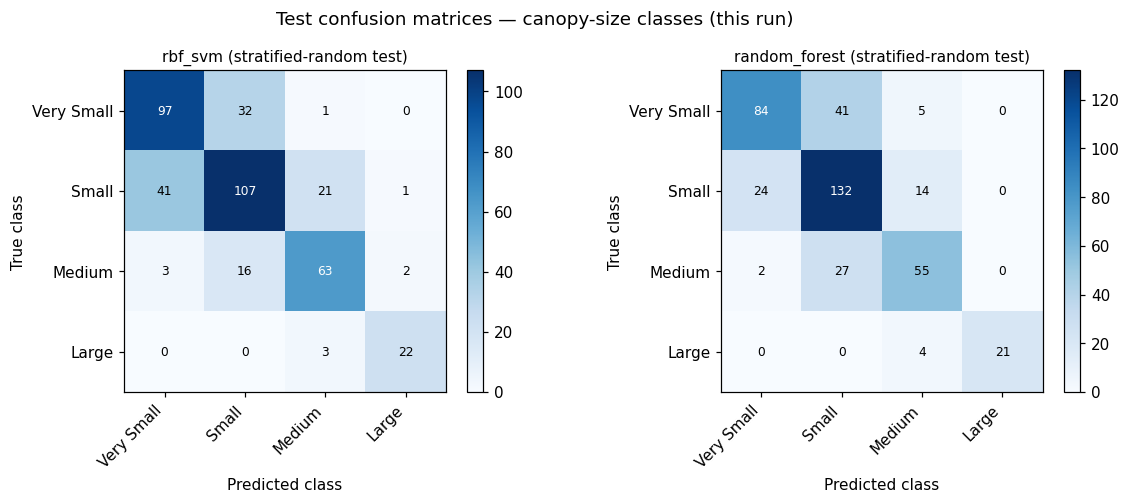

In [ ]:
import numpy as np

figure, axes = plt.subplots(1, 2, figsize=(11, 4.6), dpi=110)
for axis, algorithm in zip(axes, ["rbf_svm", "random_forest"]):
    matrix = pd.read_csv(
        experiment_dir / "stratified_random" / algorithm /
        "morphology_color_texture" / "test_confusion_matrix.csv",
        index_col="true_class",
    )
    image = axis.imshow(matrix.to_numpy(), cmap="Blues")
    axis.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    axis.set_yticks(range(len(matrix.index)), matrix.index)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("True class")
    axis.set_title(f"{algorithm} (stratified-random test)", fontsize=10)
    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            axis.text(column, row, matrix.to_numpy()[row, column],
                      ha="center", va="center",
                      color="white" if matrix.to_numpy()[row, column] > matrix.to_numpy().max() / 2 else "black",
                      fontsize=8)
    figure.colorbar(image, ax=axis, fraction=0.046)
figure.suptitle("Test confusion matrices — canopy-size classes (this run)")
figure.tight_layout()
plt.show()

## Interpretation, scope, and validation record

**What was reproduced.** The paper's classical image-descriptor baseline subsection: automatic ExG+Otsu segmentation, the 22 morphology/colour/GLCM descriptors, and RBF-SVM/Random-Forest canopy-size classification over the paper's four evaluation splits, using the authors' unmodified pinned code (`a9be840397fc06522889cbfcee0b928d1002196c`) and their published dataset (Zenodo 19597014, MD5-verified).

**How to read the results.** The session-held-out mean ± SD rows can be compared directly with the abstract's quoted values (RBF-SVM balanced accuracy 54.13 ± 4.95%; the table above shows this run's values). The step-10 table quantifies the difference from the authors' committed reference run of the same subsection. As the paper itself reports, both classical classifiers stay well above the 0.25 random baseline but below the supervised transfer-learning result.

**Out of scope.** The β-VAE latent-map descriptors (C1–C5) and the EfficientNet-B0 baseline: no trained weights are released, so those subsections would require full retraining and are not attempted here. Polygon annotations are not used by this baseline (the pipeline builds its own masks); training the deep models and the uncertainty/robustness controls (scripts 08–09, 20, 25–27) are likewise not part of this demonstration.

**Validation record.** Executed end-to-end in a fresh Colab CPU runtime on 2026-11-26 (see the environment and timing outputs above); the delivered notebook's embedded outputs are from that run.

**日本語:** 本ノートブックは論文の古典記述子ベースライン部分を、著者のピン留めコードと公開データセット (MD5 検証済み) でそのまま再現しました。S1–S3 の mean ± SD は要約筆記の 54.13 ± 4.95% (RBF-SVM) と直接比較できます。β-VAE と EfficientNet-B0 は重み未公開のため対象外です。

**References.** Paper: Agronomy 16(21):2222 (2026), doi:10.3390/agronomy16212222. Code: `agmzaman/BlueberryLatentMapPhenotyping` @ `a9be840397fc06522889cbfcee0b928d1002196c` (MIT). Dataset: Zenodo record 19597014 (CC-BY-4.0).